# Link of Stream A and Stream B: Decisions on Detector Alarms

**Master's Thesis Project:** Seasonality-Aware Drift Detection System  
**Week 4:** the backtest of stream B takes its decisions at the alarms of a drift detector instead of on a weekly calendar. The detector is a black box that writes one file of alarms; the strategies that review the model on alarm are compared with the weekly ones on the same 263 series, and the cost of false alarms shows up in retrainings and checks on series without a change.

Until the detector of stream A delivers its alarms, two stand-in detectors run on the same series, both using only the past: `profile_conformal` (the residual of each hour from the median of the same hour of the last 4 weeks, a conformal threshold on the last 2 weeks of residuals, two consecutive violations, one-day cooldown; the rule of the stream A detector) and `adwin` (ADWIN on the same residuals). Both are calibrated per source on a control period without changes to one false alarm per 14 days.

Computed by `python -m src.recommendations.alarms` (alarms) and `python -m src.recommendations.run_backtest --alerts data/alerts/alerts.csv --advisors rules` (strategies on alarm); the results are read from `data/alerts/` and `data/processed/stream_b/`. The rows of the weekly strategies are the same as in `03_stream_b_acceptance_rule.ipynb`.

In [1]:
# Import required libraries
import sys
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Adds the parent directory (project root) to the Python path
sys.path.append(os.path.abspath(os.path.join('..')))

from src.recommendations.alarms import TARGET_DAYS, read_alerts
from src.recommendations.backtester import ALARM_STRATEGIES, STRATEGIES, VAL_WEEKS, backtest, check_action, make_actor
from src.recommendations.catalog import ACTIONS
from src.recommendations.forecast import DAY, WEEK, Model, mase_scale
from src.recommendations.plots import LINE, STYLE, label_of, plot_quality_cost, tag_detector

RESULTS = "../data/processed/stream_b"
runs = pd.read_csv(f"{RESULTS}/runs.csv")
summary = pd.read_csv(f"{RESULTS}/summary.csv")
summary["detector"] = summary.detector.fillna("")
alerts = pd.read_csv("../data/alerts/alerts.csv")
detectors = pd.read_csv("../data/alerts/detectors.csv")
KEY = ["source", "series", "scenario"]
DETECTORS = sorted(alerts.method.unique())
print("Detectors:", ", ".join(DETECTORS), "|", len(alerts), "alarms on", alerts.id.nunique(), "series")

Detectors: adwin, profile_conformal | 3921 alarms on 263 series


## 1. The Alarms

One row per alarm: `id` (`source/series/scenario`, as in the manifest of `src/data`), `method`, `timestamp` and `index` (the position in the series), plus the score and the threshold of the detector. The backtest matches the alarms to its series by `id` and `timestamp`; the detector itself can be anything that writes this file.

In [2]:
display(alerts.head())
print("Calibrated settings per source (target: one false alarm per", TARGET_DAYS, "days):")
display(detectors)

,id,source,series,scenario,method,timestamp,index,score,threshold
0,entsoe/IT/lockdown_2020,entsoe,IT,lockdown_2020,profile_conformal,2020-03-12 07:00:00+00:00,27967,5320.75,3768.2
1,entsoe/IT/lockdown_2020,entsoe,IT,lockdown_2020,profile_conformal,2020-03-13 07:00:00+00:00,27991,6905.75,5328.1
2,entsoe/IT/lockdown_2020,entsoe,IT,lockdown_2020,profile_conformal,2020-05-01 06:00:00+00:00,29166,9969.00,7630.3
3,entsoe/IT/lockdown_2020,entsoe,IT,lockdown_2020,profile_conformal,2020-06-01 05:00:00+00:00,29909,5865.00,3076.3
4,entsoe/IT/lockdown_2020,entsoe,IT,lockdown_2020,profile_conformal,2020-06-02 05:00:00+00:00,29933,11212.00,7610.3


Calibrated settings per source (target: one false alarm per 14 days):


,source,method,param,value,far_control_per_1000,target_per_1000,control_windows,control_hours
0,seismic,profile_conformal,mult,1.600000,2.300,2.976,15,14784
1,seismic,adwin,delta,0.300000,1.759,2.976,15,14784
2,synthetic,profile_conformal,mult,1.200000,2.558,2.976,60,141120
3,synthetic,adwin,delta,0.003000,2.615,2.976,60,141120
4,entsoe,profile_conformal,mult,1.600000,1.931,2.976,8,63168
5,entsoe,adwin,delta,0.000001,8.295,2.976,8,63168


Alarms per 1000 hours after deployment, per source and scenario. On the control series (`synthetic / none`) every alarm is false; the settings calibrated on them give the target rate there. On the real series the settings come from a control period of the same source (the year 2019 for the national load, the weeks before the measures for the seismic noise).

In [3]:
from src.recommendations.synthetic import SYN_WEEKS

hours = (runs[runs.strategy == "nothing"].assign(hours=lambda d: d.t_stop.fillna(SYN_WEEKS * WEEK) - d.t_deploy)
         .groupby(["source", "scenario"]).hours.sum())
per = alerts.groupby(["source", "scenario", "method"]).size().rename("alarms").reset_index()
per["per_1000h"] = [1000 * a / hours[(s, c)] for s, c, a in zip(per.source, per.scenario, per.alarms)]
per.pivot(index=["source", "scenario"], columns="method", values="per_1000h").round(2)

method                   adwin  profile_conformal
source    scenario                               
entsoe    lockdown_2020   8.27               1.61
seismic   lockdown_2020   2.38               2.15
synthetic level_shift     3.44               2.81
          none            2.61               2.56
          trend_ramp      3.47               2.72
          variance        3.17               3.67

## 2. Strategies on Alarm

Each strategy takes the same decision as its weekly counterpart, but at the first origin after an alarm; alarms in the 7 days after a review are ignored, and the gated and advised ones decide only once they have two weeks of their own forecasts to check against. `alarm_oracle` chooses the best action in hindsight at the alarm times: the ceiling for that timing.

In [4]:
pd.DataFrame([(s.name, s.title, s.policy, s.action or "", s.advisor or "", s.gate or s.policy == "gated", s.cooldown_days)
              for s in ALARM_STRATEGIES],
             columns=["strategy", "description", "policy", "action", "advisor", "acceptance rule", "cooldown days"])

,strategy,description,policy,action,advisor,acceptance rule,cooldown days
0,alarm_retrain,"retrain on a detector alarm, no backtest check",fixed,retrain_full,,False,7
1,alarm_gate,"retrain on an alarm, only if the backtest chec...",gated,retrain_full,,True,7
2,alarm_catalog_gate,"on an alarm, the best catalog action among tho...",gated,,,True,7
3,alarm_oracle,oracle on an alarm: the best catalog action in...,oracle,,,False,7
4,alarm_rules,"on an alarm, rules on the diagnostics, no back...",advised,,rules,False,7
5,alarm_rules_gate,"on an alarm, rules on the diagnostics with the...",advised,,rules,True,7
6,alarm_llm,"on an alarm, LLM, no backtest check",advised,,llm,False,7
7,alarm_llm_gate,"on an alarm, LLM with the diagnostics and the ...",advised,,llm,True,7


## 3. Results: Strategy x Detector

Mean over series per source and scenario. `alarms` counts the detector alarms after deployment, `acts_pre` the model changes before the change of the series (all of them on a series without one: the cost of false alarms, or of a fixed calendar), `reaction_h` the hours from the change to the first model change after it, `check_fits` the model fits the checks needed.

In [5]:
SHOW = ["nothing", "scheduled", "scheduled_gate", "catalog_gate", "rules_gate", "oracle_weekly",
        "alarm_retrain", "alarm_gate", "alarm_catalog_gate", "alarm_rules", "alarm_rules_gate", "alarm_oracle"]
cols = ["source", "scenario", "strategy", "detector", "mase_post", "retrains", "check_fits", "acts_pre", "reaction_h", "alarms"]
t = summary[summary.strategy.isin(SHOW)].copy()
t["_o"] = t.strategy.map(SHOW.index)
pd.set_option("display.max_rows", 200)
t.sort_values(["source", "scenario", "_o", "detector"])[cols].round(3).reset_index(drop=True)

,source,scenario,strategy,detector,mase_post,retrains,check_fits,acts_pre,reaction_h,alarms
0,entsoe,lockdown_2020,nothing,,0.787,0.000,NaN,NaN,NaN,NaN
1,entsoe,lockdown_2020,scheduled,,0.696,24.000,NaN,NaN,NaN,NaN
2,entsoe,lockdown_2020,scheduled_gate,,0.717,3.375,46.000,NaN,NaN,NaN
3,entsoe,lockdown_2020,catalog_gate,,0.738,6.000,230.000,NaN,NaN,NaN
4,entsoe,lockdown_2020,rules_gate,,0.780,0.000,3.500,NaN,NaN,NaN
5,entsoe,lockdown_2020,oracle_weekly,,0.607,17.500,NaN,NaN,NaN,NaN
6,entsoe,lockdown_2020,alarm_retrain,adwin,0.709,18.375,NaN,7.625,72.000,34.750
7,entsoe,lockdown_2020,alarm_retrain,profile_conformal,0.751,4.500,NaN,0.875,390.000,6.750
8,entsoe,lockdown_2020,alarm_gate,adwin,0.721,2.625,33.000,0.125,981.000,34.750
9,entsoe,lockdown_2020,alarm_gate,profile_conformal,0.749,1.250,8.750,0.000,1704.000,6.750


Weekly reference strategies against the strategies on alarm, one figure per detector:

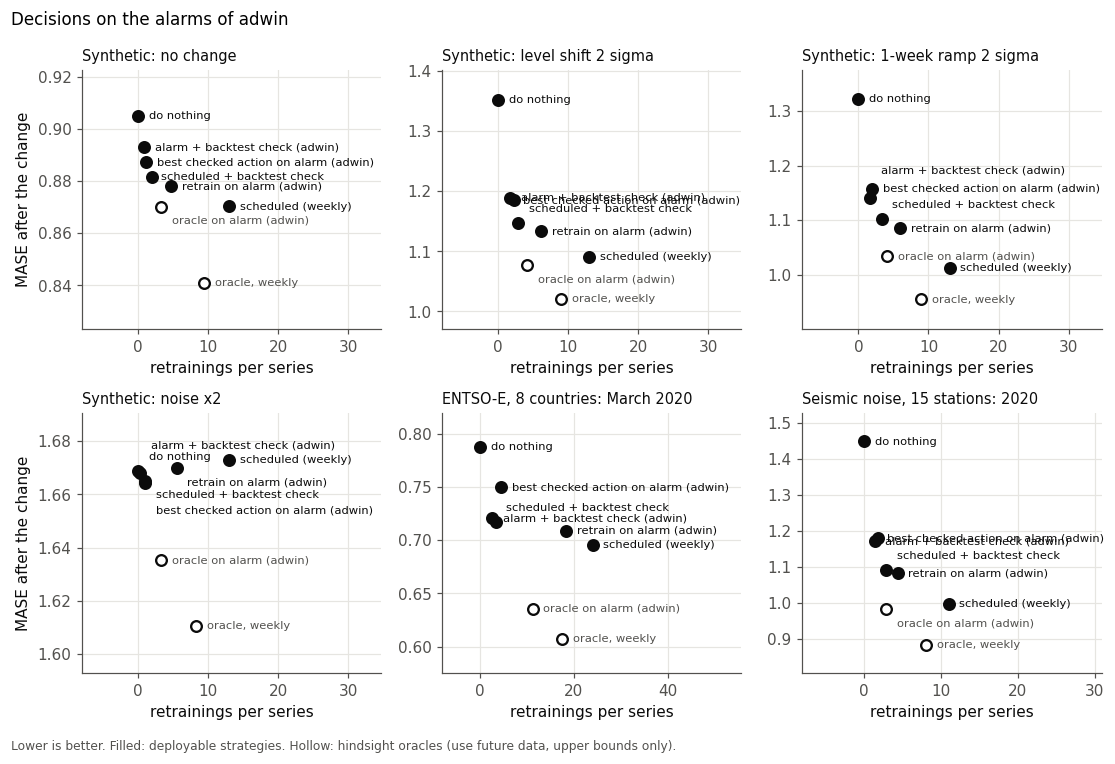

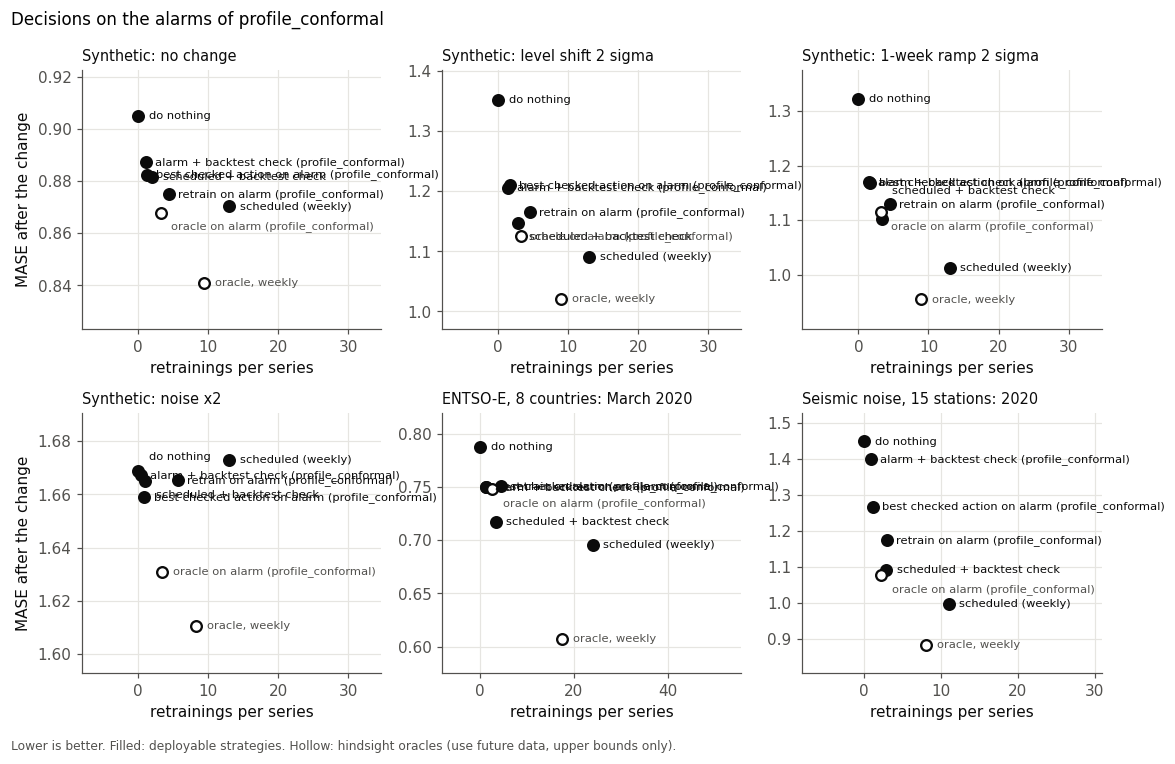

In [6]:
for det in DETECTORS:
    part = summary[summary.strategy.isin(["nothing", "scheduled", "scheduled_gate", "oracle_weekly"])
                   | (summary.strategy.isin(["alarm_retrain", "alarm_gate", "alarm_catalog_gate", "alarm_oracle"]) & (summary.detector == det))]
    fig = plot_quality_cost(tag_detector(part))
    fig.suptitle(f"Decisions on the alarms of {det}", x=0.01, y=1.03, ha="left", fontsize=11)
    plt.show()

Advised strategies on alarm, without and with the acceptance rule (the rules advisor; the LLM runs once the API key is available):

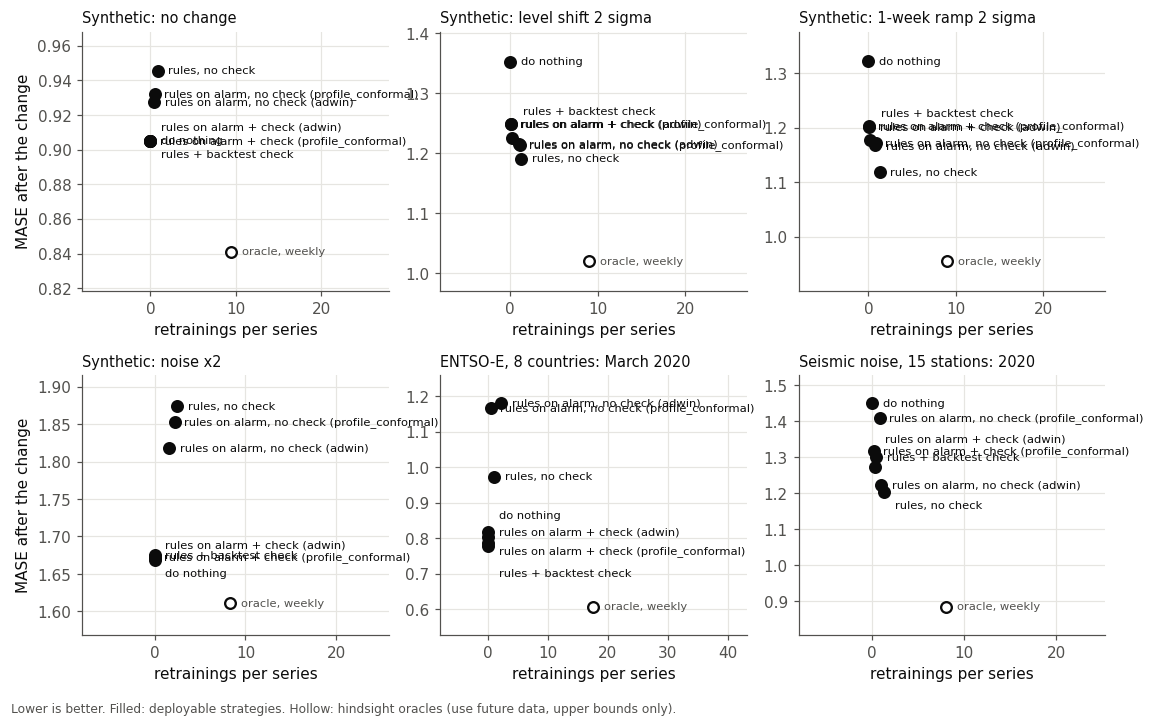

In [7]:
part = summary[summary.strategy.isin(["nothing", "rules", "rules_gate", "oracle_weekly", "alarm_rules", "alarm_rules_gate"])]
fig = plot_quality_cost(tag_detector(part))
plt.show()

## 4. What the Alarms Change

Each weekly strategy against its version on alarm, per detector: retrainings saved, MASE after the change, the share of series where the version on alarm is not worse, and the reaction time.

In [8]:
pairs = [("scheduled", "alarm_retrain"), ("scheduled_gate", "alarm_gate"), ("catalog_gate", "alarm_catalog_gate"),
         ("rules_gate", "alarm_rules_gate"), ("oracle_weekly", "alarm_oracle")]
weekly = runs[runs.detector.isna()].set_index(KEY + ["strategy"])
rows = []
for det in DETECTORS:
    on = runs[runs.detector == det].set_index(KEY + ["strategy"])
    for a, b in pairs:
        for (src, sc), g in on.xs(b, level="strategy").groupby(level=["source", "scenario"]):
            w = weekly.xs(a, level="strategy").loc[g.index]
            rows.append(dict(detector=det, source=src, scenario=sc, weekly=a, on_alarm=b, series=len(g),
                             retrains_saved=round(1 - g.retrains.mean() / w.retrains.mean(), 2) if w.retrains.mean() > 0 else np.nan,
                             mase_weekly=round(w.mase_post.mean(), 3), mase_on_alarm=round(g.mase_post.mean(), 3),
                             share_not_worse=round((g.mase_post <= w.mase_post + 1e-9).mean(), 2),
                             reaction_h_on_alarm=round(g.reaction_h.mean(), 0)))
pd.DataFrame(rows)

,detector,source,scenario,weekly,on_alarm,series,retrains_saved,mase_weekly,mase_on_alarm,share_not_worse,reaction_h_on_alarm
0,adwin,entsoe,lockdown_2020,scheduled,alarm_retrain,8,0.23,0.696,0.709,0.25,72.0
1,adwin,seismic,lockdown_2020,scheduled,alarm_retrain,15,0.60,0.998,1.084,0.07,128.0
2,adwin,synthetic,level_shift,scheduled,alarm_retrain,60,0.53,1.091,1.134,0.20,62.0
3,adwin,synthetic,none,scheduled,alarm_retrain,60,0.64,0.870,0.878,0.32,294.0
4,adwin,synthetic,trend_ramp,scheduled,alarm_retrain,60,0.54,1.013,1.086,0.05,106.0
5,adwin,synthetic,variance,scheduled,alarm_retrain,60,0.58,1.673,1.670,0.62,144.0
6,adwin,entsoe,lockdown_2020,scheduled_gate,alarm_gate,8,0.22,0.717,0.721,0.38,981.0
7,adwin,seismic,lockdown_2020,scheduled_gate,alarm_gate,15,0.52,1.092,1.173,0.20,439.0
8,adwin,synthetic,level_shift,scheduled_gate,alarm_gate,60,0.40,1.147,1.189,0.22,521.0
9,adwin,synthetic,none,scheduled_gate,alarm_gate,60,0.58,0.882,0.893,0.13,925.0


## 5. The Cost of False Alarms

On the control series (no change) every model change is a false move. Retrainings, checks and model fits per series over 14 weeks after deployment, weekly strategies against the strategies on alarm:

In [9]:
none = summary[(summary.source == "synthetic") & (summary.scenario == "none")
               & summary.strategy.isin(["scheduled", "scheduled_gate", "catalog_gate", "alarm_retrain", "alarm_gate", "alarm_catalog_gate"])]
none[["strategy", "detector", "alarms", "retrains", "check_fits", "mase_post"]].round(3).reset_index(drop=True)

,strategy,detector,alarms,retrains,check_fits,mase_post
0,scheduled,,NaN,13.000,NaN,0.870
1,scheduled_gate,,NaN,2.017,24.000,0.882
2,catalog_gate,,NaN,2.733,120.000,0.874
3,alarm_retrain,adwin,6.150,4.667,NaN,0.878
4,alarm_retrain,profile_conformal,6.017,4.417,NaN,0.875
5,alarm_gate,adwin,6.150,0.850,7.933,0.893
6,alarm_gate,profile_conformal,6.017,1.117,7.433,0.887
7,alarm_catalog_gate,adwin,6.150,1.117,39.667,0.887
8,alarm_catalog_gate,profile_conformal,6.017,1.233,37.167,0.883


## 6. The Chain on One Series

The Milan seismic station (IV.MILN) around the measures of March 2020: the alarms of both detectors, the review at the first origin after an alarm, the diagnostics the advisor sees, its recommendation, the acceptance rule on the two weeks before the review, and the forecasts of the model with and without the chain.

In [10]:
from src.data.frames import series_id, series_table
from src.recommendations.data_sources import seismic_series
from src.recommendations.llm_client import RuleAdvisor, diagnostics

(s,) = seismic_series("../data/raw/seismic_noise", stations=("IV.MILN",))
sid = series_id(s)
mine = read_alerts("../data/alerts/alerts.csv", series_table([s]))[sid]
stamps = pd.date_range(s["start"], periods=len(s["y"]), freq="1h")
print("change (first measures):", stamps[s["t_change"]])
for det, idx in mine.items():
    near = [i for i in idx if s["t_change"] - 2 * WEEK <= i < s["t_change"] + 2 * WEEK]
    print(f"{det}: {len(idx)} alarms after deployment; around the change:", ", ".join(str(stamps[i]) for i in near))

change (first measures): 2020-03-08 00:00:00
adwin: 3 alarms after deployment; around the change: 2020-03-13 16:00:00
profile_conformal: 3 alarms after deployment; around the change: 2020-03-14 06:00:00


In [11]:
det = "profile_conformal"
first = int(next(i for i in mine[det] if i >= s["t_change"]))
T = s["t_deploy"] + ((first - s["t_deploy"]) // DAY + 1) * DAY  # the first origin after the alarm
scale = mase_scale(s["y"][: s["t_deploy"]])
nothing = backtest(s["y"], s["F"], s["t_deploy"], STRATEGIES[0], s["base_features"])
ctx = diagnostics(s["y"], nothing["pred"], T, s["t_deploy"], scale, s["t_deploy"], alarm=dict(method=det, hours_ago=int(T - first)))
rec = RuleAdvisor().recommend(ctx)
print("review at", stamps[T], "| diagnostics:", {k: v for k, v in ctx.items() if k != "alarm"})
print("rules advisor:", rec.action, "-", rec.reason)
act = make_actor(s["F"], s["y"], s["base_features"])
model, _ = act(ACTIONS["retrain_full"], Model(s["base_features"]), s["t_deploy"])
if rec.action != "keep":
    print("acceptance rule:", check_action(ACTIONS[rec.action], model, s["y"], s["F"], nothing["pred"], T, scale, act))

review at 2020-03-15 00:00:00 | diagnostics: {'mase_first_weeks': 0.7, 'mase_last_weeks': [0.96, 1.08, 1.09], 'bias_last_week': -0.0, 'level_change': -1.01, 'amplitude_ratio': 1.01, 'noise_ratio': 1.19, 'weeks_since_change': 5.9, 'weeks_of_history': 18.9}
rules advisor: retrain_2w - error ratio 1.56, model 5.9 weeks old
acceptance rule: {'action': 'retrain_2w', 'gain': 0.3690211129172204, 'lo': 0.190191522932063, 'hi': 0.6623646341373608, 'accepted': True, 'fits': 2}


alarm_retrain: model changed at ['2020-03-15 00:00:00', '2020-03-30 00:00:00', '2020-04-14 00:00:00'] | picks: [] | retrains: 3
alarm_rules_gate: model changed at ['2020-03-15 00:00:00', '2020-03-30 00:00:00'] | picks: ['retrain_2w', 'retrain_2w', 'keep'] | retrains: 2


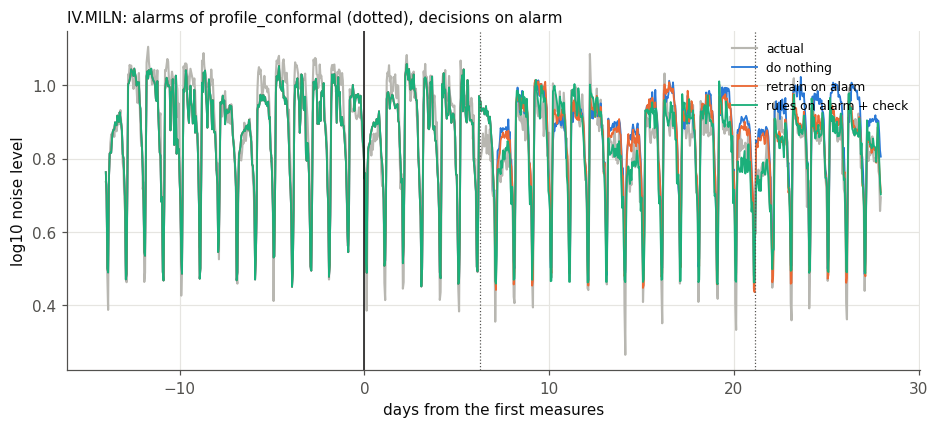

In [12]:
BY = {st.name: st for st in ALARM_STRATEGIES}
chain = {name: backtest(s["y"], s["F"], s["t_deploy"], BY[name], s["base_features"], alarms=mine[det], detector=det,
                        advisors={"rules": RuleAdvisor()})
         for name in ("alarm_retrain", "alarm_rules_gate")}
for name, r in chain.items():
    print(f"{name}: model changed at", [str(stamps[t]) for t in r["applied"]], "| picks:", r["picks"], "| retrains:", r["retrains"])
lo, hi = s["t_change"] - 2 * WEEK, s["t_change"] + 4 * WEEK
rows = np.arange(lo, hi)
days = (rows - s["t_change"]) / DAY
with plt.rc_context(STYLE):
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(days, s["y"][rows], color="#b8b7b1", lw=1.4, label="actual")
    ax.plot(days, nothing["pred"][rows], color=LINE["nothing"], lw=1.2, label=label_of("nothing"))
    for (name, r), color in zip(chain.items(), (LINE["scheduled"], LINE["oracle"])):
        ax.plot(days, r["pred"][rows], color=color, lw=1.2, label=label_of(name))
    for i in mine[det]:
        if lo <= i < hi:
            ax.axvline((i - s["t_change"]) / DAY, color="#52514e", lw=0.8, ls=":")
    ax.axvline(0, color="#0b0b0b", lw=1)
    ax.set_xlabel("days from the first measures")
    ax.set_ylabel("log10 noise level")
    ax.set_title(f"IV.MILN: alarms of {det} (dotted), decisions on alarm", loc="left", fontsize=10)
    ax.legend(loc="upper right", fontsize=8)
    plt.show()

## 7. Consistency Checks

In [13]:
on = runs[runs.detector.notna()]
print("alarm strategies run once per detector and series:", bool((on.groupby(KEY + ["strategy"]).detector.nunique() == len(DETECTORS)).all()))
print("no alarms -> no model change:", bool((on[on.alarms == 0].retrains == 0).all()), f"({(on.alarms == 0).sum()} runs without alarms)")
gated = on[on.strategy.isin(["alarm_gate", "alarm_catalog_gate", "alarm_rules_gate"])]
print("accepted <= proposed <= decisions:", bool(((gated.accepted <= gated.proposed.fillna(gated.decisions))
      & (gated.proposed.fillna(gated.decisions) <= gated.decisions)).all()))
weekly = runs[runs.detector.isna() & runs.strategy.isin([s.name for s in STRATEGIES])]
old = pd.read_csv(f"{RESULTS}/summary.csv")
print("weekly rows present for every series:", int(weekly.groupby(KEY).size().min()), "strategies per series")

alarm strategies run once per detector and series: True
no alarms -> no model change: True (54 runs without alarms)
accepted <= proposed <= decisions: True
weekly rows present for every series: 7 strategies per series


## 8. Findings

All numbers are means over the series of a source and scenario (tables above), MASE after the change with the retrainings per series in brackets.

- **A detector's false alarm rate has to be calibrated per source.** The settings calibrated on the synthetic control series gave 15.8 alarms per 1000 hours on the national load (six times the target) and 1.4 on the seismic noise. Calibrated on a control period of each source, the conformal stand-in meets the target on all three (1.9, 2.3 and 2.6 per 1000 hours); ADWIN does not reach it on the national load even at its strictest setting (8.3): the residual from the 4-week profile drifts with the season there, and ADWIN keeps splitting its window. This is the recipe for the detector of stream A: one threshold per source, chosen on control data, and methods compared at the same false alarm rate.
- **Retraining on alarm saves most retrainings at the price of a later reaction.** National load: 0.751 (4.5) with the conformal stand-in and 0.709 (18.4) with ADWIN against 0.696 (24) for weekly retraining; seismic noise: 1.084 (4.4) with ADWIN against 0.998 (11); synthetic level shift: 1.134 (6.1) against 1.091 (13). The alarms save 55% to 80% of the retrainings for 0.01 to 0.09 MASE, and the difference is the reaction time: 62 hours (ADWIN) to 146 hours (conformal) after the synthetic shift, 128 to 253 hours on the seismic noise, 72 to 390 hours on the national load.
- **Sparse alarms cap what any advisor can do.** `alarm_oracle`, the best action in hindsight at the alarm times, is close to the weekly oracle where alarms are frequent (national load with ADWIN 0.636 against 0.607, synthetic shift 1.077 against 1.021) and far from it where they are sparse (national load with the conformal stand-in 0.748, seismic noise 0.98 to 1.08 against 0.885). The choice of the action still matters more than its timing, but a detector that alarms once a month leaves little to choose.
- **The cost of false alarms is visible and small.** On the control series the strategies on alarm retrain 4.4 to 5.1 times per series in 14 weeks (one alarm every two to three weeks, as calibrated) against 13 weekly retrainings, with the same error (0.875 against 0.870); with the acceptance rule 0.9 to 1.1 (scheduled_gate: 2.0). With doubled noise, retraining on alarm does no harm (1.665, the level of doing nothing) while weekly retraining does a little (1.673).
- **The acceptance rule on alarm reacts slowly.** `alarm_gate` and `alarm_catalog_gate` change the model 400 to 1700 hours after the change (3 to 10 weeks): the review at the first alarm after the change replays the action on two weeks that are mostly before the change and rejects it, and the next review waits for the next alarm, weeks later. The check needs two weeks of evidence after the change; on a calendar it gets them at the next weekly review, on alarms only at the next alarm. The fix to try: keep a rejected proposal pending and re-check it daily (two fits a day for one action) until it passes or two weeks have gone by.
- **Advice without the check is as bad on alarm as on the calendar.** The rules advisor applied on alarm is far worse than doing nothing on the national load (1.17 to 1.18 against 0.787) and with doubled noise (1.82 to 1.85 against 1.669); with the check it returns to 0.80 to 0.82 and 1.67. This is the same protection the acceptance rule gave the weekly strategies.
- **Neither stand-in dominates.** ADWIN reacts faster on the synthetic shift and does better on the seismic noise; the conformal rule meets the target rate on the national load where ADWIN does not. The comparison at equal false alarm rate is the fair one, and it is the one the detector of stream A will be read in.

## 9. Next Steps

- Replace the stand-in detectors by the alarms of the stream A detector (a causal version: the decomposition at time T must use data before T only), written to the same file; calibrate its sensitivity per source on the same control periods.
- The LLM advisor on alarm (`alarm_llm`, `alarm_llm_gate`) once the API key is available; the alarm (method and hours since) is already part of the prompt.
- Tune the check window and the cooldown on the validation series only, not on these.